# Tutorial 04: Large cells on the sparse backend

In this tutorial you compute the density of states (DOS) and the Boltzmann transport tensors of a 16-atom Si supercell on the sparse backend of PAOFLOW, the route for cells whose Hamiltonian on the k-mesh does not fit in memory. You switch the script of [Tutorial 01](tutorial01.ipynb) to the sparse backend, build the supercell by doubling the two-atom cell along each lattice vector, compute both properties in one loop over the k-mesh, and check the result against the dense pipeline of Tutorial 01 on the two-atom cell. The physics of each property stays that of Tutorials 01 and 02. What changes is how the Hamiltonian is stored and diagonalised, and with it come two approximations: a truncated real-space Hamiltonian and a limited set of solved states. The methods are the constructor {py:class}`~PAOFLOW.PAOFLOW.PAOFLOW` with `sparse=True`, {py:meth}`~PAOFLOW.PAOFLOW.PAOFLOW.doubling_Hamiltonian`, the `fused()` block of the backend, {py:meth}`~PAOFLOW.PAOFLOW.PAOFLOW.save_sparse_hamiltonian` and {py:meth}`~PAOFLOW.PAOFLOW.PAOFLOW.load_sparse_hamiltonian`.

**What you will compute**

- How the memory of the dense pipeline grows with the size of the cell, which decides when to switch.
- The PAO Hamiltonian as a list of hoppings, truncated at a neighbour shell.
- A $2\times2\times2$ Si supercell, and how its Hamiltonian grows on each pipeline.
- The DOS and transport tensors of the supercell from one loop over the k-mesh, and the states that loop solves.
- A comparison with the dense pipeline that separates the error of the backend from that of the truncation.

:::{tip}
{download}`Download this notebook <tutorial04.ipynb>`. It uses the same input as Tutorial 01, the file `tutorial_assets.tar.gz` of the release [tutorial-assets-v2](https://github.com/marcobn/PAOFLOW/releases/tag/tutorial-assets-v2), which the first code cell downloads and extracts next to the notebook unless `tutorial01/silicon.save` is already there. The notebook runs in about a minute on 4 cores and needs about 2.5 GB of memory. This tutorial assumes [Tutorial 01](tutorial01.ipynb) and, for the transport tensors, [Tutorial 02](tutorial02.ipynb).
:::

## Required input

The input is the QE calculation of bulk Si described in the [Required input of Tutorial 01](tutorial01.ipynb#required-input). The sparse backend needs nothing more from the DFT run, but the DFT k-grid, $12\times12\times12$ here, matters more than on the dense pipeline: it sets the extent of the grid of lattice vectors $\mathbf{R}$ on which $H(\mathbf{R})$ is defined, and with it the longest bond a truncation can keep (see [How to choose the truncation of the sparse Hamiltonian](../howtos/sparse-truncation.md)).

In [1]:
from pathlib import Path
from tarfile import open as open_tar
from urllib.request import urlretrieve

savedir = 'tutorial01/silicon.save'
outputdir = 'output'

# fetch the input of this tutorial from the release named in the tip, unless it is here already
if not Path(savedir).is_dir():
    archive = Path('tutorial_assets.tar.gz')
    if not archive.is_file():
        urlretrieve(
            'https://github.com/marcobn/PAOFLOW/releases/download/'
            'tutorial-assets-v2/tutorial_assets.tar.gz',
            archive,
        )
    with open_tar(archive, 'r:gz') as tar:
        members = [m for m in tar.getmembers() if m.name.startswith('tutorial01/')]
        tar.extractall(members=members, filter='data')

## 1. When the dense pipeline runs out of memory

You switch to the sparse backend when the arrays of the dense pipeline do not fit in the memory of a node. The dense pipeline keeps three arrays on the interpolated k-mesh: the Hamiltonian $\tilde H(\mathbf{k})$, its gradient with three components, and the eigenvectors. Each component holds $N_\mathrm{mesh}\, n_\mathrm{awf}^2$ complex numbers of 16 bytes, where $N_\mathrm{mesh}$ is the number of k-points of the mesh and $n_\mathrm{awf}$ the number of PAOs in the cell, so together they take

$$
M_\mathrm{dense} = 5 \times 16\, N_\mathrm{mesh}\, n_\mathrm{awf}^2 \ \mathrm{bytes}.
$$

In a supercell of $N$ primitive cells, $n_\mathrm{awf}$ grows as $N$, while the number of k-points that samples the Brillouin zone with the same density falls as $1/N$, so $M_\mathrm{dense}$ grows as $N$. The cell below evaluates it for Si supercells at the k-point density of the $24\times24\times24$ mesh of Tutorial 01.

In [2]:
def dense_memory_gb(n_awf, n_mesh):
    """Memory of H(k), its three gradient components and the eigenvectors on the mesh (GB)."""
    return 5 * 16 * n_mesh * n_awf**2 / 1e9


print(' atoms  orbitals   mesh  memory (GB)')
for doublings, mesh in [(0, 24), (1, 12), (2, 6), (3, 3)]:
    cells = 8**doublings  # each doubling along the three lattice vectors multiplies the cell by 8
    n_awf = 18 * cells  # two Si atoms per primitive cell, nine PAOs per atom
    print(f'{2 * cells:6d} {n_awf:9d}  {mesh:2d}^3 {dense_memory_gb(n_awf, mesh**3):12.1f}')

 atoms  orbitals   mesh  memory (GB)
     2        18  24^3          0.4
    16       144  12^3          2.9
   128      1152   6^3         22.9
  1024      9216   3^3        183.5


Each doubling of the cell along the three lattice vectors multiplies the memory by 8: 0.4 GB for the two-atom cell, 2.9 GB for 16 atoms, 23 GB for 128 atoms and 184 GB for 1024 atoms. Defect supercells, slabs, interfaces and heterostructures therefore exhaust the memory of a node. To avoid this, the sparse backend never forms these arrays. Instead, it stores $H(\mathbf{R})$ as a list of hoppings, builds $\tilde H(\mathbf{k})$ at one k-point at a time, and discards it and its eigenvectors before the next.

Use the dense pipeline whenever it fits in memory, because it has every PAOFLOW method and needs no truncation. This tutorial uses the 16-atom cell, which still fits, so that you can compare the two pipelines in Section 5.

## 2. Switching the script to the sparse backend

You switch the script with two arguments of the constructor: `sparse=True`, and the options of the backend in the dictionary `sparse_config`, all listed in {py:class}`~PAOFLOW.sparse.config.SparseConfig`. Every other method keeps the name and arguments it has on the dense pipeline.

The first three calls run as on the dense pipeline, on the DFT cell. At the end of `pao_hamiltonian()` the backend converts $H_{\alpha\beta}(\mathbf{R})$ to a list of hoppings, one entry per pair of orbitals $\alpha\beta$ and lattice vector $\mathbf{R}$, and drops the hoppings on bonds longer than the 36th neighbour shell, the set of bonds of the 36th distinct length. This truncation is the first approximation of the backend. A cutoff on the bond length keeps or drops whole shells, so it keeps the crystal symmetry, and for Si it moves the bands within 2 eV of the valence-band maximum (VBM) by up to 93 meV; [How to choose the truncation of the sparse Hamiltonian](../howtos/sparse-truncation.md) explains how to choose it for your material. The truncation is applied once, here, and stays fixed for the rest of the run.

The last call saves the truncated $H(\mathbf{R})$ of the two-atom cell for the check of Section 5. Only the DFT cell has a well-defined set of bonds, so the file is written before the cell is doubled.

In [3]:
from PAOFLOW import PAOFLOW

paoflow = PAOFLOW.PAOFLOW(
    savedir=savedir,
    outputdir=outputdir,
    smearing='gauss',
    sparse=True,
    sparse_config={'bond_order': 36},
)
paoflow.read_atomic_proj_QE()
paoflow.projectability()
paoflow.pao_hamiltonian()  # H(R) becomes a list of hoppings, truncated at the 36th shell
paoflow.save_sparse_hamiltonian('silicon_bo36.npz')  # to outputdir, for the check of Section 5


────────────────────────────────────────────────────────────────────────────────────
   
           ██████╗  █████╗  ██████╗ ███████╗██╗      ██████╗ ██╗    ██╗
           ██╔══██╗██╔══██╗██╔═══██╗██╔════╝██║     ██╔═══██╗██║    ██║
           ██████╔╝███████║██║   ██║█████╗  ██║     ██║   ██║██║ █╗ ██║
           ██╔═══╝ ██╔══██║██║   ██║██╔══╝  ██║     ██║   ██║██║███╗██║
           ██║     ██║  ██║╚██████╔╝██║     ███████╗╚██████╔╝╚███╔███╔╝
           ╚═╝     ╚═╝  ╚═╝ ╚═════╝ ╚═╝     ╚══════╝ ╚═════╝  ╚══╝╚══╝
           
────────────────────────────────────────────────────────────────────────────────────
   From DFT wavefunctions to materials properties via atomic-orbital Hamiltonians   
────────────────────────────────────────────────────────────────────────────────────

Serial execution
Initialization in:                          0.009 sec


Projectability in:                          2.064 sec


Building Hks in:                            0.580 sec


k -> R in:                                  0.020 sec


Sparse conversion in:                       0.058 sec


save_sparse_hamiltonian in:                 0.276 sec


In [4]:
import re
from pathlib import Path


def show_log(title):
    """Print one section of sparse.log, the log the sparse backend writes to outputdir."""
    text = Path(outputdir, 'sparse.log').read_text()
    print(re.search(rf'^{re.escape(title)}\n.*?(?=\n\n|\Z)', text, re.M | re.S).group(0))


show_log('Hamiltonian (base cell)')

Hamiltonian (base cell)
-----------------------
  cutoff radius (Bohr)   32.129  (bond length of neighbour shell 36)
  hopping threshold (eV) none
  orbitals (nawf)        18
  R vectors              1728
  bonds kept             0.153M of 0.56M  (27.3%)
  bond list (MB)         7.6
  dense H(R) (MB)        8.5
  max eigenvalue shift from truncation (eV)  4.11


The backend writes this log, `sparse.log`, to the output directory, one section per step. Here it kept 27.3% of the 0.56 million elements of $H(\mathbf{R})$, 7.6 MB against 8.5 MB for the dense array. For the two-atom cell the saving is small; what matters is how the two grow with the cell, which Section 3 shows. The last line is a rigorous bound on the shift the truncation can cause in any eigenvalue at any k-point, 4.11 eV, far above the 93 meV by which the bands actually move, so the truncation how-to measures the shift on the bands instead.

## 3. A 16-atom cell by doubling

`doubling_Hamiltonian(1, 1, 1)` doubles the cell along each of the three lattice vectors, which gives a $2\times2\times2$ supercell of 16 atoms and 144 PAOs. It builds $H(\mathbf{R})$ of the supercell by rearranging the hoppings of the two-atom cell, so it needs no new DFT calculation, and the bands of the supercell are those of the two-atom cell folded into its eight times smaller Brillouin zone. In this tutorial the supercell stands in for a large cell from a DFT calculation, such as a defect supercell or a slab, whose $H(\mathbf{R})$ you would build with the first three calls of Section 2.

Call the doubling before `bands()` and every property, because the first band or property calculation fixes the number of bands for the cell; a doubling after it stops with `call doubling_Hamiltonian() before bands() and the properties`.

In [5]:
paoflow.doubling_Hamiltonian(1, 1, 1)  # before bands() and every property
show_log('Doubling (nx, ny, nz = 1, 1, 1)')

doubling_Hamiltonian in:                    2.744 sec


Doubling (nx, ny, nz = 1, 1, 1)
-------------------------------
  cells                  8  (2^3)
  orbitals (nawf)        18 -> 144
  bonds                  0.153M -> 1.22M
  peak memory per rank (GB)  0.52
  available per rank (GB)  39.79  (80% of MemAvailable 49.7 GB, shared by 1 rank on this node)
  steady memory per rank (GB)  0.03
  dense H(k) per k-point (GB)  0.00
  H(k) solver after doubling  dense (LAPACK)
  bonds after doubling   1.22M
  bond list after doubling (MB)  60.7
  max eigenvalue shift from truncation (eV)  4.11



The hopping list grows by a factor of 8, from 0.153 to 1.22 million hoppings (60.7 MB), in proportion to the number of atoms, because each atom keeps the same bonds. A dense $H(\mathbf{R})$ on the same $\mathbf{R}$ grid holds every pair of orbitals, so it grows by a factor of 64, to about 540 MB. The log also gives the memory the doubling needs at its peak, 0.52 GB per MPI rank, against the memory available to each rank. When the peak exceeds it, the backend warns with `doubling_Hamiltonian may run out of memory: ...` and continues; in that case double fewer times, truncate more, or start fewer ranks per node.

## 4. DOS and transport of the supercell in one pass

You now compute the DOS and the transport tensors of the supercell. The Brillouin zone of the supercell is eight times smaller than that of the two-atom cell, so a $12\times12\times12$ mesh samples it with the density of the $24\times24\times24$ mesh of Tutorial 01. On the sparse backend `interpolated_hamiltonian()` only records this mesh, because the hopping list gives $\tilde H(\mathbf{k})$ at any $\mathbf{k}$.

The script has no `pao_eigh()`, `gradient_and_momenta()` or `adaptive_smearing()`, because on the sparse backend these calls compute nothing. On the dense pipeline, `pao_eigh()` diagonalises $\tilde H(\mathbf{k})$ at every k-point and keeps all eigenvectors for the steps that follow, which is the array a large cell cannot afford. The sparse backend instead diagonalises one k-point at a time, computes there everything the properties of the script need (eigenvalues, band velocities, adaptive smearing widths, projections for the projected DOS), and discards the eigenvectors before the next k-point. One such loop over all k-points of the mesh is called a pass. Since only the properties tell the pass what to compute, the pass runs when a property needs it, and the three methods only store their arguments for it; a script that keeps their defaults leaves them out.

The calls inside the `fused()` block are collected, and one pass serves all of them when the block ends. After a pass only the eigenvalues and band velocities stay in memory, so a property that needs only these, such as `transport()` after `dos()`, reuses them. A property that needs the eigenvectors, such as `dielectric_tensor()`, called after the pass, starts a second pass that repeats every diagonalisation, and the run reports `Sparse mesh pass 2 recomputes the whole mesh for ...`. The block also matters for correctness, because a pass solves only the states up to the highest energy range among its properties (see the output below). A property called after the pass with a higher range would find states missing, so the backend stops with `requested emax = ... lies above the lowest solved top band` instead of returning an incomplete result. Therefore put all properties of the run in one `fused()` block.

For a cell with many atoms, pass `do_pdos=False` to `dos()` unless you need the projected DOS, because by default it writes one file per orbital, thousands of files for a large supercell.

In [6]:
paoflow.interpolated_hamiltonian(nfft1=12, nfft2=12, nfft3=12)  # the density of 24^3 for 2 atoms
with paoflow.sparse.fused():
    paoflow.dos(emin=-12.0, emax=2.2, ne=1000, do_pdos=False)
    paoflow.transport(emin=-12.0, emax=2.2)
show_log('Solve window (mesh pass 1)')

R -> k with Zero Padding in:                0.006 sec


Sparse mesh pass in:                       43.958 sec


DoS in:                                     1.676 sec


Transport in:                               1.639 sec


Solve window (mesh pass 1)
--------------------------
  properties             dos, transport
  probe                  16 k-points; largest adaptive width 0.674 eV (afac 0.70, k spacing 0.0392 1/Bohr)
  smearing margin (eV)   2.694  (4 x the largest adaptive width)
  thermal margin (eV)    0.259 at 300 K  (10 kT)
  dos range (eV)         [-12.000, 2.200]  + smearing margin
  transport range (eV)   [-12.000, 2.200]  + thermal margin at 300 K
  window (eV)            bottom of the spectrum to 4.894
  bands per k-point      62 of 144  (54 states below the window top at the probe points, padded to 62)


The log shows the second approximation of the backend: each pass solves only the states from the bottom of the spectrum up to the highest energy range of its properties plus a margin. Here the range ends at `emax` = 2.2 eV, and the margin is four times the largest adaptive smearing width, 2.694 eV, because a state of width $\sigma$ still contributes to the DOS about $4\sigma$ from its energy. The pass therefore solves the 62 lowest of the 144 states at each k-point, up to 4.894 eV, while the dense pipeline would solve all of them. [How to choose which states the sparse backend solves](../howtos/sparse-states.md) explains the margins, the properties that need every state, and the two options that change the states solved. With 62 of 144 states the pass diagonalises each $\tilde H(\mathbf{k})$ in full, one k-point at a time; [the eigensolver of the sparse backend](../../internals/sparse-eigensolver.md) explains when it switches to an iterative solver instead.

The warning about adaptive widths below the energy grid spacing concerns the DOS on this mesh and is the same as on the dense pipeline; [Tutorial 01, section 6](tutorial01.ipynb#6-band-velocities-and-adaptive-smearing) explains the `min_width` that removes it, which you pass to `adaptive_smearing()` before the `fused()` block.

**Output:** `output/dosdk_0.dat` holds the DOS of the 16-atom cell, and `sigmagauss_0.dat`, `Seebeckgauss_0.dat`, `kappagauss_0.dat` and `PFgauss_0.dat` the transport tensors, in the format of Tutorials 01 and 02.

## 5. Checking the result against the dense pipeline

You check the backend by computing the same properties on the dense pipeline of Tutorial 01, for the two-atom cell, from the truncated $H(\mathbf{R})$ saved in Section 2. Both runs then share the truncation, so any difference comes from the sparse backend itself: the folding into the supercell and the limited set of solved states. The truncation error is a separate question, which you test by varying `bond_order` as the [truncation how-to](../howtos/sparse-truncation.md) shows.

With `restart=True` the constructor reads no DFT data, and `load_sparse_hamiltonian()` takes the place of `read_atomic_proj_QE()`, `projectability()` and `pao_hamiltonian()`, so this run needs neither `silicon.save` nor the projections. The calls that follow are those of Tutorial 01.

In [7]:
dense = PAOFLOW.PAOFLOW(outputdir='output_dense', restart=True, smearing='gauss')
dense.load_sparse_hamiltonian('output/silicon_bo36.npz')  # replaces the first three steps
dense.interpolated_hamiltonian()
dense.pao_eigh()
dense.gradient_and_momenta()
dense.adaptive_smearing()
dense.dos(emin=-12.0, emax=2.2, ne=1000, do_pdos=False)
dense.transport(emin=-12.0, emax=2.2)


────────────────────────────────────────────────────────────────────────────────────
   
           ██████╗  █████╗  ██████╗ ███████╗██╗      ██████╗ ██╗    ██╗
           ██╔══██╗██╔══██╗██╔═══██╗██╔════╝██║     ██╔═══██╗██║    ██║
           ██████╔╝███████║██║   ██║█████╗  ██║     ██║   ██║██║ █╗ ██║
           ██╔═══╝ ██╔══██║██║   ██║██╔══╝  ██║     ██║   ██║██║███╗██║
           ██║     ██║  ██║╚██████╔╝██║     ███████╗╚██████╔╝╚███╔███╔╝
           ╚═╝     ╚═╝  ╚═╝ ╚═════╝ ╚═╝     ╚══════╝ ╚═════╝  ╚══╝╚══╝
           
────────────────────────────────────────────────────────────────────────────────────
   From DFT wavefunctions to materials properties via atomic-orbital Hamiltonians   
────────────────────────────────────────────────────────────────────────────────────

Run starting from Restart data.
Initialization in:                          0.000 sec


Loaded truncated Hamiltonian from output/silicon_bo36.npz
  152766 bonds, threshold = 0.0e+00 eV, bond_order = 36 (r_c = 32.129 Bohr), eig_bound = 4.111e+00 eV
load_sparse_hamiltonian in:                 0.054 sec


New estimated maximum array size: 0.86 GBytes
R -> k with Zero Padding in:                0.143 sec


Eigenvalues in:                             0.913 sec


Gradient in:                                0.959 sec


Momenta in:                                 1.074 sec


Adaptive Smearing in:                       0.127 sec


DoS (Adaptive Smearing) in:                 1.738 sec


Transport in:                               1.745 sec


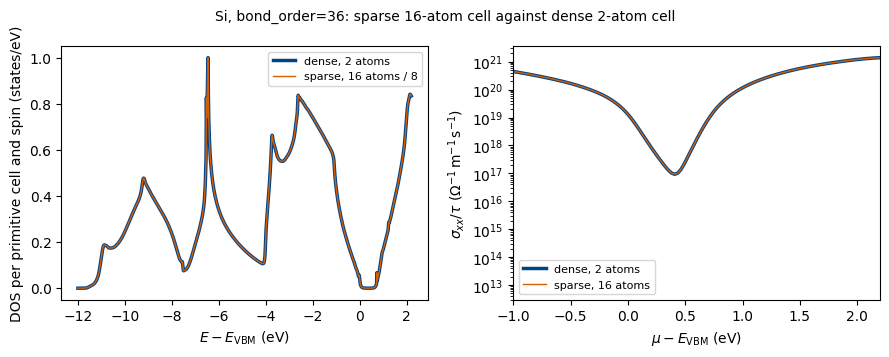

largest |DOS difference| / largest DOS: 3.3e-07
largest relative sigma_xx difference where sigma_xx > 1e-3 of its maximum: 4.4e-06


In [8]:
import matplotlib.pyplot as plt
import numpy as np

energy, dos_cell = np.loadtxt('output/dosdk_0.dat', unpack=True)
_, dos_dense = np.loadtxt('output_dense/dosdk_0.dat', unpack=True)
dos_sparse = dos_cell / 8  # the 16-atom cell holds eight primitive cells
sigma_sparse = np.loadtxt('output/sigmagauss_0.dat')
sigma_dense = np.loadtxt('output_dense/sigmagauss_0.dat')
mu = sigma_dense[:, 1]

fig, (left, right) = plt.subplots(1, 2, figsize=(9.0, 3.6))
left.plot(energy, dos_dense, color='#004488', lw=2.5, label='dense, 2 atoms')
left.plot(energy, dos_sparse, color='#D55E00', lw=1.0, label='sparse, 16 atoms / 8')
left.set_xlabel(r'$E - E_\mathrm{VBM}$ (eV)')
left.set_ylabel('DOS per primitive cell and spin (states/eV)')
left.legend(fontsize=8)
right.semilogy(mu, sigma_dense[:, 2], color='#004488', lw=2.5, label='dense, 2 atoms')
right.semilogy(mu, sigma_sparse[:, 2], color='#D55E00', lw=1.0, label='sparse, 16 atoms')
right.set_xlim(-1.0, 2.2)
right.set_xlabel(r'$\mu - E_\mathrm{VBM}$ (eV)')
right.set_ylabel(r'$\sigma_{xx}/\tau$ ($\Omega^{-1}\,\mathrm{m}^{-1}\,\mathrm{s}^{-1}$)')
right.legend(fontsize=8)
fig.suptitle('Si, bond_order=36: sparse 16-atom cell against dense 2-atom cell', fontsize=10)
fig.tight_layout()
plt.show()

print(
    f'largest |DOS difference| / largest DOS: {np.abs(dos_sparse - dos_dense).max() / dos_dense.max():.1e}'
)
inside = sigma_dense[:, 2] > 1e-3 * sigma_dense[:, 2].max()
print(
    f'largest relative sigma_xx difference where sigma_xx > 1e-3 of its maximum: {np.max(np.abs(sigma_sparse[inside, 2] / sigma_dense[inside, 2] - 1)):.1e}'
)

The sparse run of the 16-atom cell reproduces the dense run of the two-atom cell. The figure compares the DOS per primitive cell (the DOS of the 16-atom cell divided by 8) and $\sigma_{xx}/\tau$ at 300 K, with energies relative to the VBM, and the curves lie on top of each other: the DOS differs by at most $3.3\times10^{-7}$ of its maximum, and $\sigma_{xx}/\tau$ by $4.4\times10^{-6}$ of its value wherever it exceeds $10^{-3}$ of its maximum. The folding into the supercell and the 62 solved states therefore lose nothing: with the same truncated Hamiltonian and the same k-point density, the sparse backend reproduces the dense pipeline.

On your own system, run this comparison on a smaller version of it, with fewer atoms or a coarser k-mesh, so that the dense run fits in memory. A larger difference than here points to a different truncation in the two runs, or to a solve window that ends too close to a property range; the second case is reported by a warning in `sparse.log`, whose warnings start with `WARNING:` and are also printed in the output of the run.

:::{tip}
To continue on the dense pipeline in the same run instead of through a file, call `to_dense()` directly after `pao_hamiltonian()`, before any doubling, interpolation or band calculation:

```python
paoflow.pao_hamiltonian()  # truncated with sparse_config
paoflow.to_dense()  # every later call on this object runs on the dense pipeline
```

The saved file is also how you restart a sparse run, because `restart_dump()` saves the arrays of the dense pipeline and not the hopping list: start the new run with `sparse=True` and `restart=True`, and load the file in place of the first three steps.
:::

## 6. Other properties on the sparse backend

Every property in the table below is computed with the same call as on the dense pipeline, with the arguments documented in its API entry, for example {py:meth}`~PAOFLOW.PAOFLOW.PAOFLOW.anomalous_Hall`. Add the call inside the `fused()` block of Section 4, so that it shares the pass with the other properties. A property marked "all states" sums over every pair of bands at each k-point, so its pass solves the full spectrum, which on a cell with more than 4096 orbitals stops with an error ([how-to](../howtos/sparse-states.md#properties-that-need-every-state)).

| group | methods |
| --- | --- |
| bands along a path | `bands`, `wave_function_projection`, `site_projected_bands` (all states), `berry_curvature` (all states), `topology` |
| densities and Fermi surface | `dos` (with PDOS), `density`, `fermi_surface`, `ipr`, `jdos` |
| textures | `spin_texture`, `orbital_texture` |
| transport and response | `transport` (all states with `do_hall=True`), `doping`, `conductivity`, `effective_mass` (all states), `dielectric_tensor`, `rashba_edelstein` |
| Berry phase and Hall | `berry_phase`, `anomalous_Hall`, `spin_Hall`, `orbital_Hall`, `linear_response` (all states) |
| operations on $H(\mathbf{R})$ of the DFT cell | `add_external_fields`, `adhoc_spin_orbit`, `j_to_lm_hamiltonian`, `cutting_Hamiltonian`, `write_Hamiltonian` |

The operations in the last row act on the DFT cell, so call them after `pao_hamiltonian()` and before any doubling or interpolation; those that change $H(\mathbf{R})$ truncate the result again with the same `sparse_config`.

Non-linear optics, ARPES, the Weyl-point search, the mirror Chern number, the position-dipole correction, and the phonon and electron–phonon workflows exist only on the dense pipeline. Called on the sparse backend, they stop with `PAOFLOW.X is dense-only, and this run was built with sparse=True: ...`, followed by the reason. On a cell that fits in memory, compute them on the dense pipeline from the truncated Hamiltonian, as in Section 5.

## Where to go next

- [How to choose the truncation of the sparse Hamiltonian](../howtos/sparse-truncation.md): `bond_order`, `rcut` and `hopping_threshold`, and how to converge them.
- [How to choose which states the sparse backend solves](../howtos/sparse-states.md): the solve window, `nev` and `interior_window`.
- [The eigensolver of the sparse backend](../../internals/sparse-eigensolver.md): how the states of one k-point are solved, and the limit `dense_n_max`.
- {py:class}`~PAOFLOW.sparse.config.SparseConfig`: every option of `sparse_config`, with its default.

In [9]:
from pathlib import Path

import numpy as np

log = Path('output/sparse.log').read_text()
bonds = re.search(r'^  bonds after doubling\s+(\S+)', log, re.M).group(1)
assert bonds == '1.22M', f'hoppings after doubling {bonds}'
top = float(re.search(r'^  window \(eV\)\s+bottom of the spectrum to (\S+)', log, re.M).group(1))
nev = int(re.search(r'^  bands per k-point\s+(\d+) of 144', log, re.M).group(1))
assert abs(top - 4.894) < 1e-3 and nev == 62, f'solve window top {top} eV, {nev} states per k'

energy, dos_cell = np.loadtxt('output/dosdk_0.dat', unpack=True)
_, dos_dense = np.loadtxt('output_dense/dosdk_0.dat', unpack=True)
dos_error = np.abs(dos_cell / 8 - dos_dense).max() / dos_dense.max()
assert dos_error < 1e-6, f'DOS per primitive cell, sparse 16 atoms against dense: {dos_error:.1e}'
sigma_sparse = np.loadtxt('output/sigmagauss_0.dat')[:, 2]
sigma_dense = np.loadtxt('output_dense/sigmagauss_0.dat')[:, 2]
inside = sigma_dense > 1e-3 * sigma_dense.max()
sigma_error = np.abs(sigma_sparse[inside] / sigma_dense[inside] - 1).max()
assert sigma_error < 1e-5, f'sigma_xx/tau, sparse 16 atoms against dense: {sigma_error:.1e}'